# **Dependencies Installation**

In [ ]:
!pip install padelpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 48.4 MB/s eta 0:00:00


In [ ]:
import padelpy
from padelpy import padeldescriptor
import pandas as pd
import glob

In [ ]:
!wget https://raw.githubusercontent.com/KristiadiM/Bioinfo/main/QSAR/fingerprints_xml.zip

--2025-10-09 17:30:33--  https://raw.githubusercontent.com/KristiadiM/Bioinfo/main/QSAR/fingerprints_xml.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10871 (11K) [application/zip]
Saving to: ‘fingerprints_xml.zip’

fingerprints_xml.zi 100%[===================>]  10.62K  --.-KB/s    in 0s      

2025-10-09 17:30:33 (81.7 MB/s) - ‘fingerprints_xml.zip’ saved [10871/10871]



In [ ]:
!unzip fingerprints_xml.zip

Archive:  fingerprints_xml.zip
  inflating: AtomPairs2DFingerprintCount.xml  
  inflating: AtomPairs2DFingerprinter.xml  
  inflating: EStateFingerprinter.xml  
  inflating: ExtendedFingerprinter.xml  
  inflating: Fingerprinter.xml       
  inflating: GraphOnlyFingerprinter.xml  
  inflating: KlekotaRothFingerprintCount.xml  
  inflating: KlekotaRothFingerprinter.xml  
  inflating: MACCSFingerprinter.xml  
  inflating: PubchemFingerprinter.xml  
  inflating: SubstructureFingerprintCount.xml  
  inflating: SubstructureFingerprinter.xml  


In [ ]:
# Take a look at what's in our newly downloaded and unzipped folder

xml_files = glob.glob("*.xml")
xml_files.sort()
xml_files

['AtomPairs2DFingerprintCount.xml',
 'AtomPairs2DFingerprinter.xml',
 'EStateFingerprinter.xml',
 'ExtendedFingerprinter.xml',
 'Fingerprinter.xml',
 'GraphOnlyFingerprinter.xml',
 'KlekotaRothFingerprintCount.xml',
 'KlekotaRothFingerprinter.xml',
 'MACCSFingerprinter.xml',
 'PubchemFingerprinter.xml',
 'SubstructureFingerprintCount.xml',
 'SubstructureFingerprinter.xml']

# **Data Loading and Processing**

In [ ]:
import pandas as pd

qsar_df = pd.read_csv('bioactivity_data_3class_pIC50.csv')
qsar_df

,molecule_chembl_id,canonical_smiles,bioactivity_class,pIC50
0,CHEMBL6012475,CN1C[C@@H](Cc2ccc(Cl)c(F)c2)c2nnc3cc(-c4ccnc(N...,active,9.221849
1,CHEMBL4869800,COc1cc(F)cc([C@@H](CO)NC(=O)[C@@H](C)N2Cc3ccc(...,active,8.698970
2,CHEMBL5082830,O=C1N([C@H](CO)c2cccc(Cl)c2)Cc2cc(-c3nc(NC4CCO...,active,8.236572
3,CHEMBL5796169,C[C@@H](NC(=O)CN1Cc2ccc(-c3nc(NC4CCOCC4)ncc3Cl...,active,8.619789
4,CHEMBL3975320,CC1CC(Oc2n[nH]c3cc(NC(=O)N[C@@H](c4ccccc4)C(C)...,active,9.000000
...,...,...,...,...
1331,CHEMBL5917662,Cc1ccc2[nH]nc(-c3ccc(F)c(CO)c3)c2c1,intermediate,5.397940
1332,CHEMBL5876616,Cc1ccc2[nH]nc(-c3ccc4c(c3)OCO4)c2c1,intermediate,5.180456
1333,CHEMBL5801861,Cc1ccc2[nH]nc(-c3ccc(O)cc3)c2c1,intermediate,5.113509
1334,CHEMBL5770842,Cc1ccc2[nH]nc(-c3ccc(C(N)=O)cc3)c2c1,intermediate,5.408935


In [ ]:
# Remove the intermediate bioactivity_class because this class made more bias to our model

qsar_df = qsar_df[qsar_df['bioactivity_class'] != 'intermediate']
qsar_df

,molecule_chembl_id,canonical_smiles,bioactivity_class,pIC50
0,CHEMBL6012475,CN1C[C@@H](Cc2ccc(Cl)c(F)c2)c2nnc3cc(-c4ccnc(N...,active,9.221849
1,CHEMBL4869800,COc1cc(F)cc([C@@H](CO)NC(=O)[C@@H](C)N2Cc3ccc(...,active,8.698970
2,CHEMBL5082830,O=C1N([C@H](CO)c2cccc(Cl)c2)Cc2cc(-c3nc(NC4CCO...,active,8.236572
3,CHEMBL5796169,C[C@@H](NC(=O)CN1Cc2ccc(-c3nc(NC4CCOCC4)ncc3Cl...,active,8.619789
4,CHEMBL3975320,CC1CC(Oc2n[nH]c3cc(NC(=O)N[C@@H](c4ccccc4)C(C)...,active,9.000000
...,...,...,...,...
1015,CHEMBL5960388,Cc1cccc2[nH]nc(-c3ccc(O)cc3)c12,inactive,4.958607
1016,CHEMBL6062934,O=C(O)c1ccc(-c2n[nH]c3ccc(C(F)(F)F)cc23)cc1,inactive,5.000000
1017,CHEMBL5755015,Cc1ccc2[nH]nc(-c3ccc(C(=O)O)cc3)c2c1,inactive,4.769551
1018,CHEMBL5777804,O=C(O)c1ccc(-c2n[nH]c3cc(C(F)(F)F)ccc23)cc1,inactive,4.769551


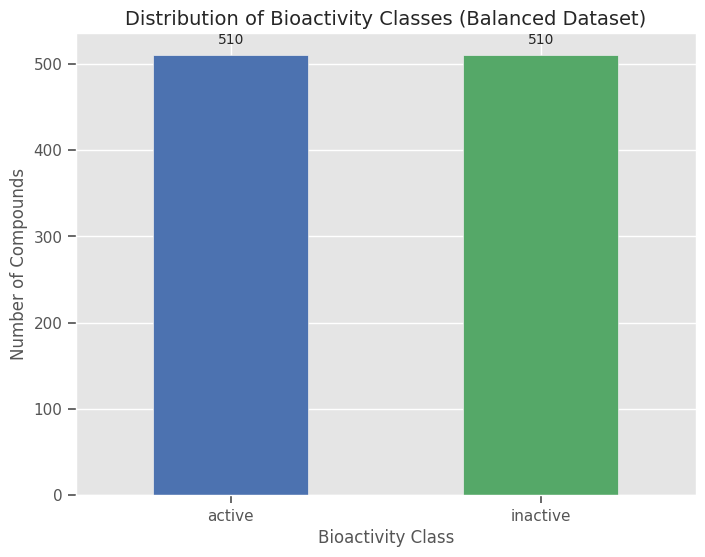

In [ ]:
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

# Calculate the counts
bioactivity_counts = qsar_df['bioactivity_class'].value_counts()

# Set the style for better visualization (optional)
plt.style.use('ggplot')

# Create the plot
plt.figure(figsize=(8, 6))

# Define colors for better clarity (e.g., matching the order in value_counts)
class_order = bioactivity_counts.index.tolist()
color_map = {'active': '#4c72b0', 'inactive': '#55a868', 'intermediate': '#c44e52'}
plot_colors = [color_map.get(c, 'gray') for c in class_order]

# Plot the calculated counts
bioactivity_counts.plot(kind='bar', color=plot_colors)

# Add labels and title
plt.title('Distribution of Bioactivity Classes (Balanced Dataset)', fontsize=14)
plt.xlabel('Bioactivity Class', fontsize=12)
plt.ylabel('Number of Compounds', fontsize=12)

# Rotate x-axis labels for better visibility
plt.xticks(rotation=0)

# Add the counts on top of the bars
for i, count in enumerate(bioactivity_counts):
    # Adjusting vertical position (count + 10) for better spacing
    plt.text(i, count + 10, str(count), ha='center', va='bottom', fontsize=10)

/tmp/ipython-input-1218776241.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = qsar_df, palette='Set2')


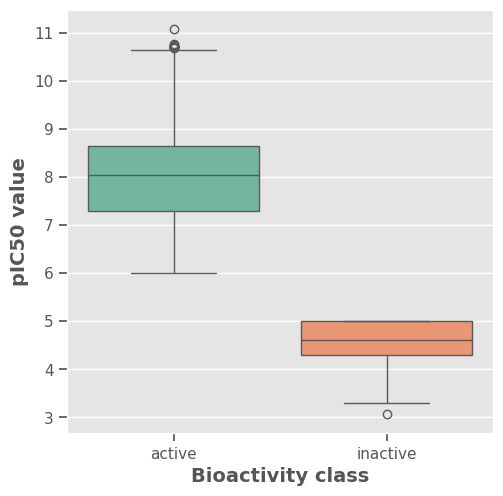

In [ ]:
# Evaluate the two classes distribution

plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = qsar_df, palette='Set2')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')

plt.savefig('plot_ic50.png')

# Normality check for our data class distribution

In [ ]:
from scipy.stats import shapiro

# Identify the two unique classes
classes = qsar_df['bioactivity_class'].unique()
if len(classes) != 2:
    raise ValueError("DataFrame does not contain exactly two unique classes in the 'bioactivity_class' column.")

class_1_name = classes[0]
class_2_name = classes[1]

# Shapiro Wilk Test

def run_shapiro_wilk(data_series, class_name):
    """
    Performs the Shapiro-Wilk test and prints the result.
    Null Hypothesis (H0): The data is drawn from a normally distributed population.
    """
    # Extract the data
    data_points = data_series.dropna()

    if len(data_points) < 3:
        print(f"\n[!] WARNING: Cannot test class '{class_name}'. Requires at least 3 data points.")
        return

    # Perform the Shapiro-Wilk test
    stat, p_value = shapiro(data_points)

    print(f"\n--- Shapiro-Wilk Test for: '{class_name}' ---")
    print(f"Sample Size (N): {len(data_points)}")
    print(f"Test Statistic (W): {stat:.4f}")
    print(f"P-value: {p_value:.5f}")

    # Decision rule (using common significance level alpha = 0.05)
    alpha = 0.05
    if p_value > alpha:
        print(f"Conclusion: P > {alpha}. We DO NOT reject the Null Hypothesis.")
        print("          -> The distribution appears statistically NORMAL.")
    else:
        print(f"Conclusion: P <= {alpha}. We REJECT the Null Hypothesis.")
        print("          -> The distribution is statistically NON-NORMAL.")

    return stat, p_value

In [ ]:
# Filter data for Class 1
data_class_1 = qsar_df[qsar_df['bioactivity_class'] == class_1_name]['pIC50']
print(f"Running test for the first class: {class_1_name}")
run_shapiro_wilk(data_class_1, class_1_name)

# Filter data for Class 2
data_class_2 = qsar_df[qsar_df['bioactivity_class'] == class_2_name]["pIC50"]
print(f"\nRunning test for the second class: {class_2_name}")
run_shapiro_wilk(data_class_2, class_2_name)

Running test for the first class: active

--- Shapiro-Wilk Test for: 'active' ---
Sample Size (N): 510
Test Statistic (W): 0.9667
P-value: 0.00000
Conclusion: P <= 0.05. We REJECT the Null Hypothesis.
          -> The distribution is statistically NON-NORMAL.

Running test for the second class: inactive

--- Shapiro-Wilk Test for: 'inactive' ---
Sample Size (N): 510
Test Statistic (W): 0.8845
P-value: 0.00000
Conclusion: P <= 0.05. We REJECT the Null Hypothesis.
          -> The distribution is statistically NON-NORMAL.


(np.float64(0.8845045759256648), np.float64(4.4456225723341025e-19))

We got not normal distribution for both our class, so we need to do more statistical analysis to make sure our classes are significantly different

In [ ]:
import pandas as pd
from scipy.stats import mannwhitneyu
import numpy as np

# Identify the two unique classes
classes = qsar_df['bioactivity_class'].unique()
if len(classes) != 2:
    raise ValueError("DataFrame does not contain exactly two unique classes in the 'bioactivity_class' column.")

class_1_name = classes[0]
class_2_name = classes[1]

# Filter data for both classes
data_class_1 = qsar_df[qsar_df['bioactivity_class'] == class_1_name]['pIC50'].dropna()
data_class_2 = qsar_df[qsar_df['bioactivity_class'] == class_2_name]['pIC50'].dropna()

# Check for sufficient data
if len(data_class_1) < 2 or len(data_class_2) < 2:
    print("\n[!] ERROR: Both classes must have at least 2 data points for comparison.")
    exit()

# Mann-Whitney U Test

# Null Hypothesis (H0): The distributions (medians) of the two groups are equal.
# Alternative Hypothesis (HA): The distributions (medians) of the two groups are unequal.
u_statistic, p_value = mannwhitneyu(data_class_1, data_class_2, alternative='two-sided')

# Results and Conclusions

print(f"\n--- Mann-Whitney U Test Results ---")
print(f"Comparing Median of '{class_1_name}' (N={len(data_class_1)}) vs. '{class_2_name}' (N={len(data_class_2)})")
print(f"U-Statistic: {u_statistic:.4f}")
print(f"P-value: {p_value:.5f}")

# Decision rule (using common significance level alpha = 0.05)
alpha = 0.05
print("-" * 40)

if p_value < alpha:
    print(f"Conclusion: P < {alpha}. We REJECT the Null Hypothesis (H0).")
    print("          -> There is a statistically significant difference in the median activity between the two classes.")
else:
    print(f"Conclusion: P >= {alpha}. We DO NOT reject the Null Hypothesis (H0).")
    print("          -> There is NO statistically significant difference in the median activity between the two classes.")

# Optionally print medians for interpretation
median_1 = np.median(data_class_1)
median_2 = np.median(data_class_2)
print("-" * 40)
print(f"Median of '{class_1_name}': {median_1:.4f}")
print(f"Median of '{class_2_name}': {median_2:.4f}")


--- Mann-Whitney U Test Results ---
Comparing Median of 'active' (N=510) vs. 'inactive' (N=510)
U-Statistic: 260100.0000
P-value: 0.00000
----------------------------------------
Conclusion: P < 0.05. We REJECT the Null Hypothesis (H0).
          -> There is a statistically significant difference in the median activity between the two classes.
----------------------------------------
Median of 'active': 8.0458
Median of 'inactive': 4.6198


# Fingerprint Generation

In [ ]:
# Convert our file to smi format

fp_df = pd.concat( [qsar_df['canonical_smiles'],qsar_df['molecule_chembl_id']], axis=1 )
fp_df.to_csv('qsar_df.smi', sep='\t', index=False, header=False)
fp_df

,canonical_smiles,molecule_chembl_id
0,CN1C[C@@H](Cc2ccc(Cl)c(F)c2)c2nnc3cc(-c4ccnc(N...,CHEMBL6012475
1,COc1cc(F)cc([C@@H](CO)NC(=O)[C@@H](C)N2Cc3ccc(...,CHEMBL4869800
2,O=C1N([C@H](CO)c2cccc(Cl)c2)Cc2cc(-c3nc(NC4CCO...,CHEMBL5082830
3,C[C@@H](NC(=O)CN1Cc2ccc(-c3nc(NC4CCOCC4)ncc3Cl...,CHEMBL5796169
4,CC1CC(Oc2n[nH]c3cc(NC(=O)N[C@@H](c4ccccc4)C(C)...,CHEMBL3975320
...,...,...
1015,Cc1cccc2[nH]nc(-c3ccc(O)cc3)c12,CHEMBL5960388
1016,O=C(O)c1ccc(-c2n[nH]c3ccc(C(F)(F)F)cc23)cc1,CHEMBL6062934
1017,Cc1ccc2[nH]nc(-c3ccc(C(=O)O)cc3)c2c1,CHEMBL5755015
1018,O=C(O)c1ccc(-c2n[nH]c3cc(C(F)(F)F)ccc23)cc1,CHEMBL5777804


In [ ]:
# Fingerprints making process

for i in range(len(xml_files)):

  padeldescriptor(mol_dir='qsar_df.smi', d_file=f'{xml_files[i][:-4]}.csv',
                  descriptortypes= xml_files[i],retainorder=True,
                  fingerprints=True,d_2d=False,
                  d_3d=False)
  fp_name = f'{xml_files[i][:-4]}'
  fp = pd.read_csv(f'{fp_name}.csv')
  fp = pd.concat([qsar_df, fp.drop('Name', axis=1)], axis=1)
  fp.to_csv(f'{fp_name}.csv', index=None)
  print (f'{xml_files[i][:-4]} done')

AtomPairs2DFingerprintCount done
AtomPairs2DFingerprinter done
EStateFingerprinter done
ExtendedFingerprinter done
Fingerprinter done
GraphOnlyFingerprinter done
KlekotaRothFingerprintCount done
KlekotaRothFingerprinter done
MACCSFingerprinter done
PubchemFingerprinter done
SubstructureFingerprintCount done
SubstructureFingerprinter done


In [ ]:
import pandas as pd
import glob

# Get a list of all CSV files in the current directory
csv_files = glob.glob('*.csv')

# --- Precaution: Exclude the output file from the merge list ---
output_filename = 'final_merged_data4.csv'
if output_filename in csv_files:
    csv_files.remove(output_filename)
    print(f"Excluded '{output_filename}' from the list of files to merge.")
# ---------------------------------------------------------------

# The composite key (multiple columns) to merge on
composite_key = ['molecule_chembl_id', 'canonical_smiles', 'bioactivity_class', 'pIC50']

# Check if there are enough files to perform a merge
if len(csv_files) > 1:
    print(f"Found {len(csv_files)} files to merge one by one.")

    # ⚙️ Step 1: Load the FIRST file to start the process
    # This will be our base DataFrame that we'll keep adding to.
    merged_df = pd.read_csv(csv_files[0])
    print(f"Starting with base file: {csv_files[0]}")

    # ⚙️ Step 2: Loop through the REST of the files
    for file in csv_files[1:]:
        print(f"Merging with: {file}...")
        # Load the next file into memory
        df_to_merge = pd.read_csv(file)

        # Perform the merge. The result overwrites our main DataFrame.
        merged_df = pd.merge(merged_df, df_to_merge, on=composite_key, how='inner')

    print("\n✅ All merges successful! Here's a preview:")
    print(merged_df.head())

    # ⚙️ Step 3: Save the final, completely merged DataFrame
    merged_df.to_csv(output_filename, index=False)
    print(f"\nSaved the final result to '{output_filename}'")

elif len(csv_files) == 1:
    print("\nOnly one CSV file found. No merge needed.")
else:
    print("\n❌ No CSV files found to merge.")

In [ ]:
merged_df

,molecule_chembl_id,canonical_smiles,bioactivity_class,pIC50,AD2D1,AD2D2,AD2D3,AD2D4,AD2D5,AD2D6,...,GraphFP1015,GraphFP1016,GraphFP1017,GraphFP1018,GraphFP1019,GraphFP1020,GraphFP1021,GraphFP1022,GraphFP1023,GraphFP1024
0,CHEMBL6012475,CN1C[C@@H](Cc2ccc(Cl)c(F)c2)c2nnc3cc(-c4ccnc(N...,active,9.221849,1,1,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,CHEMBL4869800,COc1cc(F)cc([C@@H](CO)NC(=O)[C@@H](C)N2Cc3ccc(...,active,8.698970,1,1,1,0,0,1,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,CHEMBL5082830,O=C1N([C@H](CO)c2cccc(Cl)c2)Cc2cc(-c3nc(NC4CCO...,active,8.236572,1,1,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,CHEMBL5796169,C[C@@H](NC(=O)CN1Cc2ccc(-c3nc(NC4CCOCC4)ncc3Cl...,active,8.619789,1,1,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,CHEMBL3975320,CC1CC(Oc2n[nH]c3cc(NC(=O)N[C@@H](c4ccccc4)C(C)...,active,9.000000,1,1,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,CHEMBL5960388,Cc1cccc2[nH]nc(-c3ccc(O)cc3)c12,inactive,4.958607,1,1,1,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1016,CHEMBL6062934,O=C(O)c1ccc(-c2n[nH]c3ccc(C(F)(F)F)cc23)cc1,inactive,5.000000,1,1,1,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1017,CHEMBL5755015,Cc1ccc2[nH]nc(-c3ccc(C(=O)O)cc3)c2c1,inactive,4.769551,1,1,1,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1018,CHEMBL5777804,O=C(O)c1ccc(-c2n[nH]c3cc(C(F)(F)F)ccc23)cc1,inactive,4.769551,1,1,1,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Zipping all files with csv end

!zip -r fp_data.zip *.csv

  adding: AtomPairs2DFingerprintCount.csv (deflated 96%)
  adding: AtomPairs2DFingerprinter.csv (deflated 96%)
  adding: EStateFingerprinter.csv (deflated 89%)
  adding: ExtendedFingerprinter.csv (deflated 89%)
  adding: Fingerprinter.csv (deflated 89%)
  adding: GraphOnlyFingerprinter.csv (deflated 91%)
  adding: KlekotaRothFingerprintCount.csv (deflated 99%)
  adding: KlekotaRothFingerprinter.csv (deflated 98%)
  adding: MACCSFingerprinter.csv (deflated 89%)
  adding: merged_columns_unique.csv (deflated 96%)
  adding: PubchemFingerprinter.csv (deflated 93%)
  adding: SubstructureFingerprintCount.csv (deflated 96%)
  adding: SubstructureFingerprinter.csv (deflated 94%)


In [ ]:
# Automatically download the zip

from google.colab import files

files.download('fp_data.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Checking the size of our zip file

In [ ]:
import os

# Define the path to your file
file_path = '/content/fp_data.zip'

# Define the conversion factor for 1 Kilobyte (1024 bytes)
KB = 1024

try:
    # Get the file size in bytes
    size_in_bytes = os.path.getsize(file_path)

    # Convert bytes to Kilobytes
    size_in_kb = size_in_bytes / KB

    # Print the result
    print(f"File Path: {file_path}")
    print(f"Size in Bytes: {size_in_bytes:,} B")
    print(f"Size in Kilobytes: {size_in_kb:,.2f} KB")

except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please check the path.")
except Exception as e:
    print(f"An error occurred: {e}")

File Path: /content/fp_data.zip
Size in Bytes: 2,942,962 B
Size in Kilobytes: 2,873.99 KB


# **ML Model Building**

In [ ]:
# Loading the dataset

!unzip /content/fp_data.zip

Archive:  /content/fp_data.zip
  inflating: AtomPairs2DFingerprintCount.csv  
  inflating: AtomPairs2DFingerprinter.csv  
  inflating: EStateFingerprinter.csv  
  inflating: ExtendedFingerprinter.csv  
  inflating: Fingerprinter.csv       
  inflating: GraphOnlyFingerprinter.csv  
  inflating: KlekotaRothFingerprintCount.csv  
  inflating: KlekotaRothFingerprinter.csv  
  inflating: MACCSFingerprinter.csv  
  inflating: merged_columns_unique.csv  
  inflating: PubchemFingerprinter.csv  
  inflating: SubstructureFingerprintCount.csv  
  inflating: SubstructureFingerprinter.csv  


In [ ]:
import pandas as pd

merged_df = pd.read_csv('merged_columns_unique.csv')
merged_df

,molecule_chembl_id,canonical_smiles,bioactivity_class,pIC50,KRFPC1,KRFPC2,KRFPC3,KRFPC4,KRFPC5,KRFPC6,...,GraphFP1015,GraphFP1016,GraphFP1017,GraphFP1018,GraphFP1019,GraphFP1020,GraphFP1021,GraphFP1022,GraphFP1023,GraphFP1024
0,CHEMBL6012475,CN1C[C@@H](Cc2ccc(Cl)c(F)c2)c2nnc3cc(-c4ccnc(N...,active,9.221849,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,CHEMBL4869800,COc1cc(F)cc([C@@H](CO)NC(=O)[C@@H](C)N2Cc3ccc(...,active,8.698970,2,0,0,0,0,0,...,1,1,0,0,0,0,0,0,0,0
2,CHEMBL5082830,O=C1N([C@H](CO)c2cccc(Cl)c2)Cc2cc(-c3nc(NC4CCO...,active,8.236572,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,CHEMBL5796169,C[C@@H](NC(=O)CN1Cc2ccc(-c3nc(NC4CCOCC4)ncc3Cl...,active,8.619789,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,CHEMBL3975320,CC1CC(Oc2n[nH]c3cc(NC(=O)N[C@@H](c4ccccc4)C(C)...,active,9.000000,4,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,CHEMBL5960388,Cc1cccc2[nH]nc(-c3ccc(O)cc3)c12,inactive,4.958607,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1016,CHEMBL6062934,O=C(O)c1ccc(-c2n[nH]c3ccc(C(F)(F)F)cc23)cc1,inactive,5.000000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1017,CHEMBL5755015,Cc1ccc2[nH]nc(-c3ccc(C(=O)O)cc3)c2c1,inactive,4.769551,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1018,CHEMBL5777804,O=C(O)c1ccc(-c2n[nH]c3cc(C(F)(F)F)ccc23)cc1,inactive,4.769551,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Dropping several unrelated columns and separating the target (bioactivity_class)

y = merged_df['bioactivity_class']
X = merged_df.drop(['molecule_chembl_id', 'canonical_smiles', 'pIC50', 'bioactivity_class'], axis=1)

In [ ]:
# Initialize and fit the LabelEncoder on the target variable
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

In [ ]:
# Removing low-variance features

from sklearn.feature_selection import VarianceThreshold

def remove_low_variance(input_data, threshold=0.1):
    selection = VarianceThreshold(threshold)
    selection.fit(input_data)
    return input_data[input_data.columns[selection.get_support(indices=True)]]

X = remove_low_variance(X, threshold=0.1)
X

,KRFPC1,KRFPC2,KRFPC14,KRFPC16,KRFPC20,KRFPC297,KRFPC298,KRFPC302,KRFPC303,KRFPC341,...,GraphFP991,GraphFP992,GraphFP993,GraphFP994,GraphFP996,GraphFP997,GraphFP1001,GraphFP1002,GraphFP1004,GraphFP1019
0,1,0,0,0,0,2,2,0,0,0,...,0,0,0,1,0,1,1,1,1,0
1,2,0,1,1,1,2,1,0,0,0,...,0,1,1,1,1,1,1,0,1,0
2,2,0,0,0,0,6,3,0,0,2,...,0,1,1,1,1,1,1,0,1,0
3,2,0,1,1,0,7,2,0,0,2,...,0,1,1,1,1,1,1,0,1,0
4,4,0,2,1,0,2,4,0,0,0,...,1,0,0,0,0,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1016,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1017,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1018,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Splitting the dataset for model training and testing

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, stratify=y, shuffle=True, random_state=42)

In [ ]:
# Dataset size checking

X_train.shape, X_test.shape

((816, 16092), (204, 16092))

In [ ]:
# Standardize our Dataset

from sklearn.preprocessing import StandardScaler

data_scaler = StandardScaler()
data_scaler.fit(X_train)
X_train = data_scaler.transform(X_train)
X_test = data_scaler.transform(X_test)

# Use LazyPredict


In [ ]:
!pip install lazypredict

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.7/26.7 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 75.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.8/147.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 329.1/329.1 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.2/86.2 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 718.4/718.4 kB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.4/203.4 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.6/106.6 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.4/96.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/7

In [ ]:
import lazypredict
from lazypredict.Supervised import LazyClassifier

In [ ]:
clf = LazyClassifier(verbose=0,ignore_warnings=True, custom_metric=None)
models_train,predictions_train = clf.fit(X_train, X_train, y_train, y_train)
models_test,predictions_test = clf.fit(X_train, X_test, y_train, y_test)

  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 408, number of negative: 408
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.019409 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 10980
[LightGBM] [Info] Number of data points in the train set: 816, number of used features: 3059
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
'tuple' object has no attribute '__name__'
Invalid Classifier(s)


  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 408, number of negative: 408
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017702 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 10980
[LightGBM] [Info] Number of data points in the train set: 816, number of used features: 3059
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [ ]:
print("LazyClassifier Train Results:")
predictions_train

LazyClassifier Train Results:


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
ExtraTreeClassifier,1.00,1.00,1.00,1.00,0.17
DecisionTreeClassifier,1.00,1.00,1.00,1.00,0.48
CalibratedClassifierCV,1.00,1.00,1.00,1.00,13.53
LabelPropagation,1.00,1.00,1.00,1.00,0.46
ExtraTreesClassifier,1.00,1.00,1.00,1.00,1.12
RidgeClassifier,1.00,1.00,1.00,1.00,0.39
PassiveAggressiveClassifier,1.00,1.00,1.00,1.00,0.33
LogisticRegression,1.00,1.00,1.00,1.00,0.83
LinearSVC,1.00,1.00,1.00,1.00,3.34


In [ ]:
print("LazyClassifier Test Results:")
predictions_test

LazyClassifier Test Results:


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
LGBMClassifier,0.97,0.97,0.97,0.97,2.62
RandomForestClassifier,0.97,0.97,0.97,0.97,0.80
ExtraTreesClassifier,0.96,0.96,0.96,0.96,1.08
XGBClassifier,0.96,0.96,0.96,0.96,0.96
Perceptron,0.96,0.96,0.96,0.96,0.16
KNeighborsClassifier,0.95,0.95,0.95,0.95,0.19
BaggingClassifier,0.95,0.95,0.95,0.95,2.10
CalibratedClassifierCV,0.95,0.95,0.95,0.95,10.54
SGDClassifier,0.95,0.95,0.95,0.95,0.28


We got the LGBMClassifier and Random Forest Algorithm as the best algorithms, so we'll try to optimize them

# LGBM Classifier

In [ ]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 4.4 MB/s eta 0:00:00


In [ ]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from lightgbm import LGBMClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Integer

In [ ]:
# Pipeline encapsulates Variance Threshold -> Standardization -> LightGBM
pipeline_lgbm_binary = Pipeline([
    ('vt', VarianceThreshold(threshold=0.1)),  # Step 1: Feature Reduction
    ('scaler', StandardScaler()),              # Step 2: Standardization
    ('lgbm', LGBMClassifier(
        objective='binary',                    # Correct objective for two classes
        metric='auc',                          # Internal monitoring metric
        n_jobs=-1,
        random_state=42,
        boosting_type='gbdt',
    ))
])

In [ ]:
# Define the Bayesian Parameter Space
bayes_param_space_lgbm = {
    'lgbm__n_estimators': Integer(50, 500),
    'lgbm__learning_rate': Real(1e-3, 0.3, prior='log-uniform'),
    'lgbm__num_leaves': Integer(10, 50),
    'lgbm__max_depth': Integer(3, 15),
    'lgbm__min_child_samples': Integer(10, 50),
    'lgbm__subsample': Real(0.6, 0.95, prior='uniform'),
    'lgbm__colsample_bytree': Real(0.6, 0.95, prior='uniform'),
    'lgbm__reg_alpha': Real(1e-5, 10.0, prior='log-uniform'),
    'lgbm__reg_lambda': Real(1e-5, 10.0, prior='log-uniform'),

    # Optional: Tune the variance threshold if you suspect it affects performance
    # 'vt__threshold': Real(0.05, 0.3, prior='uniform'),
}

In [ ]:
# Define required variables
CV_folds = 5
total_iters = 50 # Total number of parameter settings to sample

print(f"Starting Bayesian Optimization for LightGBM ({total_iters} iterations)...")

# Use StratifiedKFold for cross-validation within the search
skf = StratifiedKFold(n_splits=CV_folds, shuffle=True, random_state=42)

bayes_search_lgbm = BayesSearchCV(
    estimator=pipeline_lgbm_binary,
    search_spaces=bayes_param_space_lgbm,
    n_iter=total_iters,
    cv=skf,
    scoring='roc_auc', # Optimizing for AUC
    verbose=3,
    n_jobs=-1,
    random_state=42
)

bayes_search_lgbm.fit(X_train, y_train)

print("Bayesian Optimization Complete.")

Starting Bayesian Optimization for LightGBM (50 iterations)...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Get the original class names using the LabelEncoder's classes_ attribute
class_names = label_encoder.classes_

# Model Evaluation
y_pred_train = bayes_search_lgbm.predict(X_train)
y_pred_test = bayes_search_lgbm.predict(X_test)

print("\n===== BEST PARAMETERS FOUND =====")
print(bayes_search_lgbm.best_params_)

print("\n===== TRAINING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_train, y_pred_train))
print(classification_report(y_train, y_pred_train, target_names=class_names))

print("\n===== TESTING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test, target_names=class_names))

print("\n===== CONFUSION MATRIX (TEST) =====")
print(confusion_matrix(y_test, y_pred_test))


===== BEST PARAMETERS FOUND =====
OrderedDict({'lgbm__colsample_bytree': 0.6, 'lgbm__learning_rate': 0.3, 'lgbm__max_depth': 15, 'lgbm__min_child_samples': 10, 'lgbm__n_estimators': 50, 'lgbm__num_leaves': 50, 'lgbm__reg_alpha': 1e-05, 'lgbm__reg_lambda': 10.0, 'lgbm__subsample': 0.95})

===== TRAINING PERFORMANCE =====
Accuracy: 0.9950980392156863
              precision    recall  f1-score   support

      active       1.00      1.00      1.00       408
    inactive       1.00      1.00      1.00       408

    accuracy                           1.00       816
   macro avg       1.00      1.00      1.00       816
weighted avg       1.00      1.00      1.00       816


===== TESTING PERFORMANCE =====
Accuracy: 0.9558823529411765
              precision    recall  f1-score   support

      active       0.95      0.96      0.96       102
    inactive       0.96      0.95      0.96       102

    accuracy                           0.96       204
   macro avg       0.96      0.96      0.

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
save_data = {
    "model": bayes_search_lgbm.best_estimator_,
    "label_encoder": label_encoder
}

joblib.dump(save_data, "bayes_search_lgbm_pipeline.joblib")
print("\n✅ Saved full pipeline and encoder as 'bayes_search_lgbm_pipeline.joblib'")


✅ Saved full pipeline and encoder as 'bayes_search_lgbm_pipeline.joblib'


In [ ]:
# Download the pipeline

from google.colab import files

files.download('bayes_search_lgbm_pipeline.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Random Forest

In [ ]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Integer

In [ ]:
# Pipeline encapsulates Variance Threshold -> Standardization -> Random Forest Classifier
pipeline_rf_binary = Pipeline([
    ('vt', VarianceThreshold(threshold=0.1)),  # Step 1: Feature Reduction
    ('scaler', StandardScaler()),              # Step 2: Standardization
    ('rf', RandomForestClassifier(            # Changed step name to 'rf'
        n_jobs=-1,
        random_state=42
    ))
])

In [ ]:
bayes_param_space_rf = {
    # Number of trees in the forest
    'rf__n_estimators': Integer(50, 500),

    # Maximum depth of the tree
    'rf__max_depth': Integer(5, 30),

    # Minimum number of samples required to split an internal node
    'rf__min_samples_split': Integer(2, 20),

    # Minimum number of samples required to be at a leaf node
    'rf__min_samples_leaf': Integer(1, 10),

    # Number of features to consider when looking for the best split
    # 'sqrt' is common, but we search a range of proportional values (0.3 to 1.0)
    'rf__max_features': Real(0.3, 1.0, prior='uniform'),
}

In [ ]:
# Define required variables (Replace with your actual data variables)
CV_folds = 5
total_iters = 50 # Total number of parameter settings to sample

print(f"Starting Bayesian Optimization for Random Forest Classifier ({total_iters} iterations)...")

# Use StratifiedKFold for cross-validation within the search
skf = StratifiedKFold(n_splits=CV_folds, shuffle=True, random_state=42)

bayes_search_rf = BayesSearchCV(
    estimator=pipeline_rf_binary, # Use the RF Pipeline
    search_spaces=bayes_param_space_rf, # Use the defined RF search space
    n_iter=total_iters,
    cv=skf,
    scoring='roc_auc', # Optimizing for AUC
    verbose=3,
    n_jobs=-1,
    random_state=42
)

bayes_search_rf.fit(X_train, y_train)

print("Bayesian Optimization Complete.")

Starting Bayesian Optimization for Random Forest Classifier (50 iterations)...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candid

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Get the original class names using the LabelEncoder's classes_ attribute
class_names = label_encoder.classes_

# Model Evaluation
y_pred_train = bayes_search_rf.predict(X_train)
y_pred_test = bayes_search_rf.predict(X_test)

print("\n===== BEST PARAMETERS FOUND =====")
print(bayes_search_rf.best_params_)

print("\n===== TRAINING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_train, y_pred_train))
print(classification_report(y_train, y_pred_train, target_names=class_names))

print("\n===== TESTING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test, target_names=class_names))

print("\n===== CONFUSION MATRIX (TEST) =====")
print(confusion_matrix(y_test, y_pred_test))


===== BEST PARAMETERS FOUND =====
OrderedDict({'rf__max_depth': 30, 'rf__max_features': 0.3, 'rf__min_samples_leaf': 4, 'rf__min_samples_split': 2, 'rf__n_estimators': 500})

===== TRAINING PERFORMANCE =====
Accuracy: 0.9816176470588235
              precision    recall  f1-score   support

      active       0.99      0.98      0.98       408
    inactive       0.98      0.99      0.98       408

    accuracy                           0.98       816
   macro avg       0.98      0.98      0.98       816
weighted avg       0.98      0.98      0.98       816


===== TESTING PERFORMANCE =====
Accuracy: 0.946078431372549
              precision    recall  f1-score   support

      active       0.96      0.93      0.95       102
    inactive       0.93      0.96      0.95       102

    accuracy                           0.95       204
   macro avg       0.95      0.95      0.95       204
weighted avg       0.95      0.95      0.95       204


===== CONFUSION MATRIX (TEST) =====
[[95  7]
 

In [ ]:
save_data = {
    "model": bayes_search_rf.best_estimator_,
    "label_encoder": label_encoder
}

joblib.dump(save_data, "bayes_search_rf_pipeline.joblib")
print("\n✅ Saved full pipeline and encoder as 'bayes_search_rf_pipeline.joblib'")


✅ Saved full pipeline and encoder as 'bayes_search_rf_pipeline.joblib'


In [ ]:
# Download the pipeline

from google.colab import files

files.download('bayes_search_rf_pipeline.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# XGBoost Classifier

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

In [ ]:
# Pipeline encapsulates Variance Threshold -> Standardization -> XGBoost
pipeline_xgb = Pipeline([
    ('vt', VarianceThreshold(threshold=0.1)),  # Step 1: Feature Reduction
    ('scaler', StandardScaler()),              # Step 2: Standardization
    ('xgb', XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',                     # Use 'logloss' (or 'error', 'auc') for binary tasks
        use_label_encoder=False,
        n_jobs=-1,
        random_state=42
    ))
])

In [ ]:
import skopt
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

# Define Hyperparameter Search Space for BayesSearchCV

bayes_param_space = {
    'xgb__n_estimators': Integer(50, 500),                   # Number of boosting rounds
    'xgb__learning_rate': Real(1e-3, 0.3, prior='log-uniform'), # Step size shrinkage
    'xgb__max_depth': Integer(3, 10),                       # Maximum tree depth
    'xgb__subsample': Real(0.6, 0.95, prior='uniform'),     # Subsample ratio of the training instance
    'xgb__colsample_bytree': Real(0.6, 0.95, prior='uniform'), # Subsample ratio of columns
    'xgb__gamma': Real(0.0, 5.0, prior='uniform'),          # Minimum loss reduction
    'xgb__reg_alpha': Real(1e-5, 100.0, prior='log-uniform'), # L1 regularization term
    'xgb__reg_lambda': Real(1e-5, 100.0, prior='log-uniform') # L2 regularization term
}

In [ ]:
# Define required variables
CV_folds = 5
total_iters = 50 # Total number of parameter settings to sample

print(f"Starting Bayesian Optimization for XGBClassifieer ({total_iters} iterations)...")

# Use StratifiedKFold for cross-validation within the search
skf = StratifiedKFold(n_splits=CV_folds, shuffle=True, random_state=42)

bayes_search_xgb = BayesSearchCV(
    estimator=pipeline_xgb,
    search_spaces=bayes_param_space, # Use the defined search space
    n_iter=50,                        # IMPORTANT: Set the total number of parameter settings to sample
    cv=skf,
    scoring='roc_auc',
    verbose=3,
    n_jobs=-1,
    random_state=42
)

# NOTE: The fit process might take a while depending on 'n_iter'
bayes_search_xgb.fit(X_train, y_train)
print("Bayesian Optimization Complete.")

Starting Bayesian Optimization for XGBClassifieer (50 iterations)...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, tota

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [22:14:17] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Bayesian Optimization Complete.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Get the original class names using the LabelEncoder's classes_ attribute
class_names = label_encoder.classes_

# Model Evaluation
y_pred_train = bayes_search_xgb.predict(X_train)
y_pred_test = bayes_search_xgb.predict(X_test)

print("\n===== BEST PARAMETERS FOUND =====")
print(bayes_search_xgb.best_params_)

print("\n===== TRAINING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_train, y_pred_train))
print(classification_report(y_train, y_pred_train, target_names=class_names))

print("\n===== TESTING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test, target_names=class_names))

print("\n===== CONFUSION MATRIX (TEST) =====")
print(confusion_matrix(y_test, y_pred_test))


===== BEST PARAMETERS FOUND =====
OrderedDict({'xgb__colsample_bytree': 0.95, 'xgb__gamma': 0.0, 'xgb__learning_rate': 0.3, 'xgb__max_depth': 6, 'xgb__n_estimators': 50, 'xgb__reg_alpha': 7.061538765689293e-05, 'xgb__reg_lambda': 1e-05, 'xgb__subsample': 0.6})

===== TRAINING PERFORMANCE =====
Accuracy: 0.9950980392156863
              precision    recall  f1-score   support

      active       1.00      0.99      1.00       408
    inactive       0.99      1.00      1.00       408

    accuracy                           1.00       816
   macro avg       1.00      1.00      1.00       816
weighted avg       1.00      1.00      1.00       816


===== TESTING PERFORMANCE =====
Accuracy: 0.9607843137254902
              precision    recall  f1-score   support

      active       0.96      0.96      0.96       102
    inactive       0.96      0.96      0.96       102

    accuracy                           0.96       204
   macro avg       0.96      0.96      0.96       204
weighted avg  

In [ ]:
# Saving the best model

save_data = {
    "model": bayes_search_xgb.best_estimator_,
    "label_encoder": label_encoder
}

joblib.dump(save_data, "best_xgb_bayes_pipeline.joblib")
print("\n✅ Saved full pipeline and encoder as 'best_perceptron_bayes_pipeline.joblib'")


✅ Saved full pipeline and encoder as 'best_perceptron_bayes_pipeline.joblib'


In [ ]:
# Download the pipeline

from google.colab import files

files.download('best_xgb_bayes_pipeline.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Bagging Classifier

In [ ]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier # Base estimator for Bagging
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

In [ ]:
# Pipeline encapsulates Variance Threshold -> Standardization -> Bagging Classifier
# Using Decision Tree as the base estimator (estimator parameter)
pipeline_bagging_binary = Pipeline([
    ('vt', VarianceThreshold(threshold=0.1)),  # Step 1: Feature Reduction
    ('scaler', StandardScaler()),              # Step 2: Standardization
    ('bag', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42), # Base Model
        n_jobs=-1,
        random_state=42,
    ))
])

In [ ]:
bayes_param_space_bagging = {
    # Number of base estimators (trees) to fit
    'bag__n_estimators': Integer(50, 500),

    # The proportion of samples (rows) drawn from X to train each base estimator
    'bag__max_samples': Real(0.5, 1.0, prior='uniform'),

    # The proportion of features (columns) drawn from X to train each base estimator
    'bag__max_features': Real(0.5, 1.0, prior='uniform'),

    # Whether samples are drawn with replacement (typically True for standard Bagging)
    'bag__bootstrap': Categorical([True, False]),

    # Whether features are drawn with replacement
    'bag__bootstrap_features': Categorical([True, False]),
}

In [ ]:
# Define required variables
CV_folds = 5
total_iters = 50 # Total number of parameter settings to sample

print(f"Starting Bayesian Optimization for Bagging Classifier ({total_iters} iterations)...")

# Use StratifiedKFold for cross-validation within the search
skf = StratifiedKFold(n_splits=CV_folds, shuffle=True, random_state=42)

bayes_search_bagging = BayesSearchCV(
    estimator=pipeline_bagging_binary,
    search_spaces=bayes_param_space_bagging,
    n_iter=total_iters,
    cv=skf,
    scoring='roc_auc', # Optimizing for AUC
    verbose=3,
    n_jobs=-1,
    random_state=42
)

bayes_search_bagging.fit(X_train, y_train)

print("Bayesian Optimization Complete.")

Starting Bayesian Optimization for Bagging Classifier (50 iterations)...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fi

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Get the original class names using the LabelEncoder's classes_ attribute
class_names = label_encoder.classes_

# Model Evaluation
y_pred_train = bayes_search_bagging.predict(X_train)
y_pred_test = bayes_search_bagging.predict(X_test)

print("\n===== BEST PARAMETERS FOUND =====")
print(bayes_search_bagging.best_params_)

print("\n===== TRAINING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_train, y_pred_train))
print(classification_report(y_train, y_pred_train, target_names=class_names))

print("\n===== TESTING PERFORMANCE =====")
print("Accuracy:", accuracy_score(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test, target_names=class_names))

print("\n===== CONFUSION MATRIX (TEST) =====")
print(confusion_matrix(y_test, y_pred_test))


===== BEST PARAMETERS FOUND =====
OrderedDict({'bag__bootstrap': True, 'bag__bootstrap_features': True, 'bag__max_features': 0.704918709308391, 'bag__max_samples': 1.0, 'bag__n_estimators': 228})

===== TRAINING PERFORMANCE =====
Accuracy: 0.9950980392156863
              precision    recall  f1-score   support

      active       1.00      0.99      1.00       408
    inactive       0.99      1.00      1.00       408

    accuracy                           1.00       816
   macro avg       1.00      1.00      1.00       816
weighted avg       1.00      1.00      1.00       816


===== TESTING PERFORMANCE =====
Accuracy: 0.9509803921568627
              precision    recall  f1-score   support

      active       0.97      0.93      0.95       102
    inactive       0.93      0.97      0.95       102

    accuracy                           0.95       204
   macro avg       0.95      0.95      0.95       204
weighted avg       0.95      0.95      0.95       204


===== CONFUSION MATRIX 

In [ ]:
# Saving the best model

save_data = {
    "model": bayes_search_bagging.best_estimator_,
    "label_encoder": label_encoder
}

joblib.dump(save_data, "bayes_search_bagging_pipeline.joblib")
print("\n✅ Saved full pipeline and encoder as 'bayes_search_bagging_pipeline.joblib'")


✅ Saved full pipeline and encoder as 'bayes_search_bagging_pipeline.joblib'


In [ ]:
# Download the pipeline

from google.colab import files

files.download('bayes_search_bagging_pipeline.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>